# Extract PPG Signal from PhysioNet CINC 2015 and MIMIC PERform

## Preliminaries

### Download PPG Dataset

In [1]:
# Download PPG dataset from PhysioNet Challenge 2015
!gdown -q 1hd4fZ23c-DWXuFbqcwM5mBnrgP0ih-ef
!unzip -q /content/physionet-cinc-2015-arrhythmia.zip

In [2]:
# Download PPG dataset from MIMIC PERform AF
!gdown -q 1bUhzRMRUH4jBItxRRLdr64ePJwYeSmxP
!unzip -q /content/mimic_perform_af_csv.zip

In [3]:
# Download PPG dataset from MIMIC PERform non-AF
!gdown -q 1L721N1eTm_PYIZE45WuSD5eDGrRnJF7e
!unzip -q /content/mimic_perform_non_af_csv.zip

### Import Python Packages

In [4]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.io
from scipy.signal import resample

## Extract Dataset

### PhysioNet Challenge 2015

In [5]:
def parse_hea_file(hea_path):
    with open(hea_path, 'r') as f:
        lines = f.readlines()

    base_info = lines[0].strip().split()
    record_name = base_info[0]
    sampling_rate = int(base_info[2])
    num_signals = int(base_info[1])

    # Channel info
    channel_names = [line.split()[-1] for line in lines[1:num_signals+1]]

    # PPG channel index (PLETH)
    try:
        ppg_index = channel_names.index("PLETH")
    except ValueError:
        raise ValueError(f"PLETH channel not found in {hea_path}")

    # Metadata: label and alarm
    label = None
    alarm_label = None

    for line in lines:
        if line.startswith("#"):
            l = line.strip().lower()
            if "true alarm" in l:
                alarm_label = True
            elif "false alarm" in l:
                alarm_label = False
            elif not label:
                label = line.strip("#").strip()

    return record_name, ppg_index, sampling_rate, label, alarm_label

In [6]:
def extract_ppg_signal(mat_path, ppg_index):
    mat_data = scipy.io.loadmat(mat_path)
    signal = mat_data['val'][ppg_index]
    return signal

In [7]:
def process_record(base_dir, filename, dataset_source):
    hea_path = os.path.join(base_dir, filename + '.hea')
    mat_path = os.path.join(base_dir, filename + '.mat')

    record_name, ppg_index, sr, label, alarm_label = parse_hea_file(hea_path)
    ppg_signal = extract_ppg_signal(mat_path, ppg_index)

    return {
        'patient_id': record_name,
        'dataset_source': dataset_source,
        'ppg_signal': ppg_signal.tolist(),
        'frequency': sr,
        'label': label,
        'alarm_label': alarm_label
    }

#### Extract All Signals

In [8]:
def process_all_records(folder_path, dataset_source):
    records = []
    for filename in os.listdir(folder_path):
        if filename.endswith(".hea"):
            base_name = os.path.splitext(filename)[0]
            hea_path = os.path.join(folder_path, base_name + '.hea')
            mat_path = os.path.join(folder_path, base_name + '.mat')

            if not os.path.exists(mat_path):
                print(f"Warning: .mat file not found for {base_name}")
                continue

            try:
                record_name, ppg_index, sr, label, alarm_label = parse_hea_file(hea_path)
                ppg_signal = extract_ppg_signal(mat_path, ppg_index)
                record = {
                    'patient_id': record_name,
                    'dataset_source': dataset_source,
                    'ppg_signal': ppg_signal.tolist(),
                    'frequency': sr,
                    'label': label,
                    'alarm_label': alarm_label
                }
                records.append(record)
            except Exception as e:
                print(f"Error processing {base_name}: {e}")

    return pd.DataFrame(records)

In [ ]:
# Extract all signal from PhysioNet Challenge 2015
folder = "/content/physionet-cinc-2015-arrhythmia"
dataset_source = "PhysioNet2015"
cinc2015_df = process_all_records(folder, dataset_source)

In [10]:
cinc2015_df.head()

,patient_id,dataset_source,ppg_signal,frequency,label,alarm_label
0,v634s,PhysioNet2015,"[2453, 3377, 3588, 3496, 3541, 3733, 3880, 390...",250,Ventricular_Tachycardia,False
1,f408s,PhysioNet2015,"[12426, 16872, 17382, 16149, 15658, 16108, 164...",250,Ventricular_Flutter_Fib,False
2,t507l,PhysioNet2015,"[6929, 7865, 6980, 6532, 7031, 7333, 7082, 694...",250,Tachycardia,True
3,b486s,PhysioNet2015,"[700, 728, 614, 627, 602, 563, 524, 503, 482, ...",250,Bradycardia,False
4,a667l,PhysioNet2015,"[4571, 5143, 4484, 4112, 4367, 4487, 4222, 402...",250,Asystole,False


#### Checking NaN on PPG Signals

In [11]:
# Add a new column to flag whether ppg_signal contains NaNs
cinc2015_df['contains_nan'] = cinc2015_df['ppg_signal'].apply(
    lambda x: np.isnan(x).any() if isinstance(x, (list, np.ndarray)) else True
)

# Show rows that contain NaN
nan_rows = cinc2015_df[cinc2015_df['contains_nan']]
print(nan_rows[['ppg_signal', 'contains_nan']])

Empty DataFrame
Columns: [ppg_signal, contains_nan]
Index: []


In [12]:
cinc2015_df = cinc2015_df.drop(columns=["contains_nan"])
cinc2015_df.head()

,patient_id,dataset_source,ppg_signal,frequency,label,alarm_label
0,v634s,PhysioNet2015,"[2453, 3377, 3588, 3496, 3541, 3733, 3880, 390...",250,Ventricular_Tachycardia,False
1,f408s,PhysioNet2015,"[12426, 16872, 17382, 16149, 15658, 16108, 164...",250,Ventricular_Flutter_Fib,False
2,t507l,PhysioNet2015,"[6929, 7865, 6980, 6532, 7031, 7333, 7082, 694...",250,Tachycardia,True
3,b486s,PhysioNet2015,"[700, 728, 614, 627, 602, 563, 524, 503, 482, ...",250,Bradycardia,False
4,a667l,PhysioNet2015,"[4571, 5143, 4484, 4112, 4367, 4487, 4222, 402...",250,Asystole,False


#### Save to JSON for All Signals

In [13]:
cinc2015_df.to_json("PPG_CINC2015.json", orient='records', lines=True)
print("JSON Finished!")

JSON Finished!


#### Retrieving PPG Signals with "True" Alarm Label

In [14]:
# Counting the number of labels
cinc2015_df['alarm_label'].sum()
cinc2015_df['label'].value_counts()

,count
label,
Ventricular_Tachycardia,284
Tachycardia,113
Asystole,106
Bradycardia,77
Ventricular_Flutter_Fib,47


In [15]:
# Counting the number of labels if alarm_label == True
cinc2015_df_true = cinc2015_df[cinc2015_df['alarm_label'] == True]
cinc2015_df_true['label'].value_counts()

,count
label,
Tachycardia,108
Ventricular_Tachycardia,61
Bradycardia,39
Asystole,17
Ventricular_Flutter_Fib,6


#### Save to JSON for Signals with True Label

In [16]:
cinc2015_df_true = cinc2015_df_true.drop(columns=['alarm_label'])

cinc2015_df_true.to_json("PPG_CINC2015_TRUE.json", orient='records', lines=True)
print("JSON Finished!")

JSON Finished!


### MIMIC PERform dataset

In [17]:
# Path to the folder where the CSV file is located
folder_path = '/content/mimic_perform_af_csv'

# List to store all data
mimic_af_data = []

# Loop through all files in a folder
for filename in os.listdir(folder_path):
    if filename.endswith('.csv') and 'mimic_perform_af' in filename:
        # Read file
        filepath = os.path.join(folder_path, filename)
        df = pd.read_csv(filepath)

        # Retrieve patient_id from filename: mimic_perform_af_001_data.csv → af_001
        patient_id = filename.replace('mimic_perform_', '').replace('_data.csv', '')

        # Get the PPG column as an array
        if 'PPG' in df.columns:
            ppg_array = df['PPG'].tolist()  # can also .values.tolist() for NumPy feel

            # Add to list as dict
            mimic_af_data.append({
                'patient_id': patient_id,
                'dataset_source': 'MIMICPERformAF',
                'ppg_signal': ppg_array,
                'frequency': 125,
                'label': 'Atrial_Fib'
            })

# Merge all into one DataFrame
mimic_af_df = pd.DataFrame(mimic_af_data)

In [18]:
# Path to the folder where the CSV file is located
folder_path = '/content/mimic_perform_non_af_csv'

# List to store all data
mimic_non_af_data = []

# Loop through all files in a folder
for filename in os.listdir(folder_path):
    if filename.endswith('.csv') and 'mimic_perform_non_af' in filename:
        # Read file
        filepath = os.path.join(folder_path, filename)
        df = pd.read_csv(filepath)

        # Retrieve patient_id from filename: mimic_perform_af_001_data.csv → af_001
        patient_id = filename.replace('mimic_perform_', '').replace('_data.csv', '')

        # Get the PPG column as an array
        if 'PPG' in df.columns:
            ppg_array = df['PPG'].tolist()  # can also .values.tolist() for NumPy feel

            # Add to list as dict
            mimic_non_af_data.append({
                'patient_id': patient_id,
                'dataset_source': 'MIMICPERformAF',
                'ppg_signal': ppg_array,
                'frequency': 125,
                'label': 'Normal_Sinus_Rhythm'
            })

# Merge all into one DataFrame
mimic_non_af_df = pd.DataFrame(mimic_non_af_data)

In [19]:
mimic_df = pd.concat([mimic_af_df, mimic_non_af_df], ignore_index=True)
mimic_df.head()

,patient_id,dataset_source,ppg_signal,frequency,label
0,af_007,MIMICPERformAF,"[0.529411764705882, 0.52156862745098, 0.513725...",125,Atrial_Fib
1,af_014,MIMICPERformAF,"[2.10263929618768, 2.07624633431085, 2.0498533...",125,Atrial_Fib
2,af_009,MIMICPERformAF,"[0.558162267839687, 0.558162267839687, 0.56011...",125,Atrial_Fib
3,af_016,MIMICPERformAF,"[1.87683284457478, 1.86901270772239, 1.8602150...",125,Atrial_Fib
4,af_015,MIMICPERformAF,"[2.1524926686217, 2.22091886608016, 2.28543499...",125,Atrial_Fib


#### Checking NaN on PPG Signals

In [20]:
# Add a new column to flag whether ppg_signal contains NaNs
mimic_df['contains_nan'] = mimic_df['ppg_signal'].apply(
    lambda x: np.isnan(x).any() if isinstance(x, (list, np.ndarray)) else True
)

# Show rows that contain NaN
nan_rows = mimic_df[mimic_df['contains_nan']]
print(nan_rows[['ppg_signal', 'contains_nan']])

                                           ppg_signal  contains_nan
0   [0.529411764705882, 0.52156862745098, 0.513725...          True
11  [0.917647058823529, 0.933333333333333, 0.94901...          True
14  [0.517647058823529, 0.517647058823529, 0.51764...          True
26  [0.380392156862745, 0.376470588235294, 0.37647...          True
27  [0.631372549019608, 0.627450980392157, 0.62745...          True
33  [nan, nan, nan, nan, nan, nan, nan, nan, nan, ...          True


In [21]:
# Delete rows by position
mimic_df = mimic_df.drop(index=[3, 5, 16, 22, 24, 29]).reset_index(drop=True)

In [22]:
mimic_df = mimic_df.drop(columns=["contains_nan"])
mimic_df.head()

,patient_id,dataset_source,ppg_signal,frequency,label
0,af_007,MIMICPERformAF,"[0.529411764705882, 0.52156862745098, 0.513725...",125,Atrial_Fib
1,af_014,MIMICPERformAF,"[2.10263929618768, 2.07624633431085, 2.0498533...",125,Atrial_Fib
2,af_009,MIMICPERformAF,"[0.558162267839687, 0.558162267839687, 0.56011...",125,Atrial_Fib
3,af_015,MIMICPERformAF,"[2.1524926686217, 2.22091886608016, 2.28543499...",125,Atrial_Fib
4,af_011,MIMICPERformAF,"[0.479960899315738, 0.47702834799609, 0.474095...",125,Atrial_Fib


#### Resampling Signals to 250 Hz

In [23]:
def resample_signal(ppg_signal, original_rate, target_rate):
    # Convert to numeric list
    ppg_signal = list(np.array(ppg_signal, dtype=np.float32))

    # Calculate target duration and length
    original_length = len(ppg_signal)
    duration_seconds = original_length / original_rate
    target_length = int(duration_seconds * target_rate)

    return resample(ppg_signal, target_length)

In [24]:
# Apply to the entire mimic dataframe
mimic_df['ppg_signal_resampled'] = mimic_df.apply(
    lambda row: resample_signal(row['ppg_signal'], row['frequency'], 250), axis=1
)

# Update sampling_rate
mimic_df['frequency'] = 250

mimic_df = mimic_df.drop(columns=['ppg_signal'])
mimic_df = mimic_df.rename(columns={'ppg_signal_resampled': 'ppg_signal'})
mimic_df = mimic_df[['patient_id', 'dataset_source', 'ppg_signal', 'frequency', 'label']]

mimic_df.head()

,patient_id,dataset_source,ppg_signal,frequency,label
0,af_007,MIMICPERformAF,"[nan, nan, nan, nan, nan, nan, nan, nan, nan, ...",250,Atrial_Fib
1,af_014,MIMICPERformAF,"[2.1026392, 2.1058927, 2.076246, 2.0538974, 2....",250,Atrial_Fib
2,af_009,MIMICPERformAF,"[0.5581623, 0.56555855, 0.5581621, 0.5546994, ...",250,Atrial_Fib
3,af_015,MIMICPERformAF,"[2.152493, 2.2678723, 2.220919, 2.2086155, 2.2...",250,Atrial_Fib
4,af_011,MIMICPERformAF,"[0.47996074, 0.4768919, 0.4770285, 0.47649467,...",250,Atrial_Fib


#### Save to JSON

In [25]:
mimic_df.to_json("PPG_MIMICAF.json", orient='records', lines=True)
print("JSON Finished!")

JSON Finished!


## Merge Dataset

### Check Type of Data

In [26]:
print(type(cinc2015_df_true['patient_id'].iloc[0]))
print(type(cinc2015_df_true['dataset_source'].iloc[0]))
print(type(cinc2015_df_true['ppg_signal'].iloc[0][0]))
print(type(cinc2015_df_true['frequency'].iloc[0]))
print(type(cinc2015_df_true['label'].iloc[0]))
print('--------------------------------------------')
print(type(mimic_df['patient_id'].iloc[0]))
print(type(mimic_df['dataset_source'].iloc[0]))
print(type(mimic_df['ppg_signal'].iloc[0][0]))
print(type(mimic_df['frequency'].iloc[0]))
print(type(mimic_df['label'].iloc[0]))

<class 'str'>
<class 'str'>
<class 'int'>
<class 'numpy.int64'>
<class 'str'>
--------------------------------------------
<class 'str'>
<class 'str'>
<class 'numpy.float32'>
<class 'numpy.int64'>
<class 'str'>


In [27]:
cinc2015_df_true['ppg_signal'] = cinc2015_df_true['ppg_signal'].apply(
    lambda x: np.array(x, dtype=np.float32)
)

### Merge

In [28]:
ppg_df = pd.concat([cinc2015_df_true, mimic_df], ignore_index=True)

In [29]:
print(type(ppg_df['patient_id'].iloc[0]))
print(type(ppg_df['dataset_source'].iloc[0]))
print(type(ppg_df['ppg_signal'].iloc[0][0]))
print(type(ppg_df['frequency'].iloc[0]))
print(type(ppg_df['label'].iloc[0]))

<class 'str'>
<class 'str'>
<class 'numpy.float32'>
<class 'numpy.int64'>
<class 'str'>


In [30]:
ppg_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   patient_id      260 non-null    object
 1   dataset_source  260 non-null    object
 2   ppg_signal      260 non-null    object
 3   frequency       260 non-null    int64 
 4   label           260 non-null    object
dtypes: int64(1), object(4)
memory usage: 10.3+ KB


### Save to JSON

In [31]:
ppg_df = ppg_df.drop(columns=['patient_id', 'dataset_source'])

In [32]:
ppg_df.to_json("PPG_CINC2015_MIMICAF_250Hz.json", orient='records', lines=True)
print("JSON Finished!")

JSON Finished!


## Segmentation

In [33]:
def data_segmentation(df, segment_duration):
    segments = []

    for _, row in df.iterrows():
        signal = row['ppg_signal']
        fs = row['frequency']
        segment_len = int(segment_duration * fs)
        total_len = len(signal)

        num_segments = total_len // segment_len

        for i in range(num_segments):
            start = i * segment_len
            end = start + segment_len
            segment = signal[start:end]

            if len(segment) == segment_len:
                segments.append({
                    'ppg_signal': segment,
                    'frequency': fs,
                    'label': row['label']
                })

    return pd.DataFrame(segments)

In [34]:
ppg_df_segment = data_segmentation(ppg_df, 10)

In [35]:
ppg_df_segment['label'].unique()

array(['Tachycardia', 'Ventricular_Tachycardia', 'Bradycardia',
       'Asystole', 'Ventricular_Flutter_Fib', 'Atrial_Fib',
       'Normal_Sinus_Rhythm'], dtype=object)

In [36]:
ppg_df_segment = ppg_df_segment[ppg_df_segment['label'] != 'Asystole']

In [37]:
ppg_df_segment['label'].value_counts()

,count
label,
Tachycardia,3390
Atrial_Fib,1920
Ventricular_Tachycardia,1914
Normal_Sinus_Rhythm,1560
Bradycardia,1224
Ventricular_Flutter_Fib,192


In [38]:
ppg_df_segment.to_json("PPG_CINC2015_MIMICAF_SEGMENT_250Hz.json", orient='records', lines=True)
print("JSON Finished!")

JSON Finished!


### Plot Signal

In [39]:
def plot_ppg_signal(title, signal, frequency, start_time, end_time):
    fs = frequency

    start_signal_index = int(start_time * fs)
    end_signal_index = int(end_time * fs)

    signal_segment = signal[start_signal_index:end_signal_index]
    t = np.arange(len(signal_segment)) / fs

    plt.figure(figsize=(16, 4))
    plt.plot(t, signal_segment, label='PPG Signal')
    plt.xlabel('Time (s)')
    plt.ylabel('Amplitude')
    plt.title(title)
    plt.grid(True)
    plt.legend()
    plt.show()

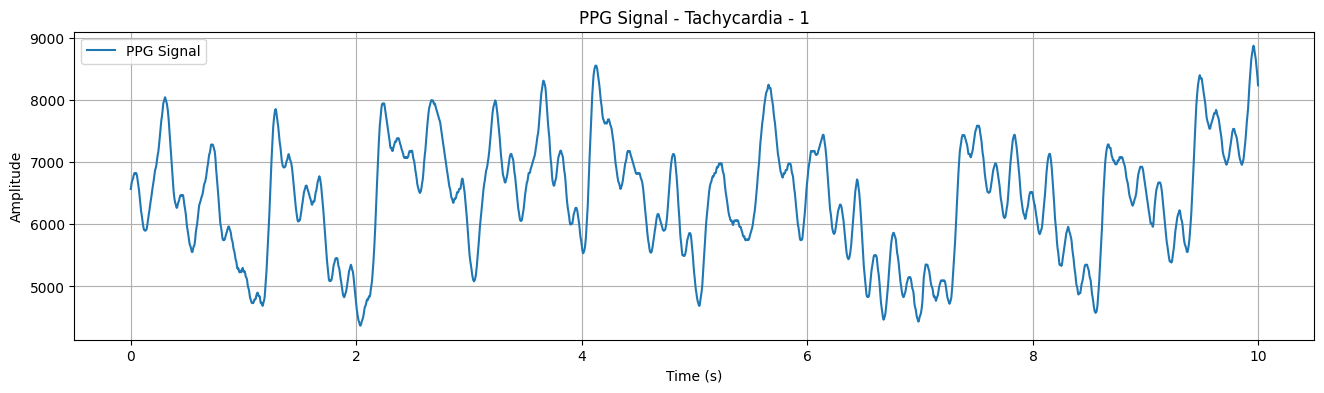

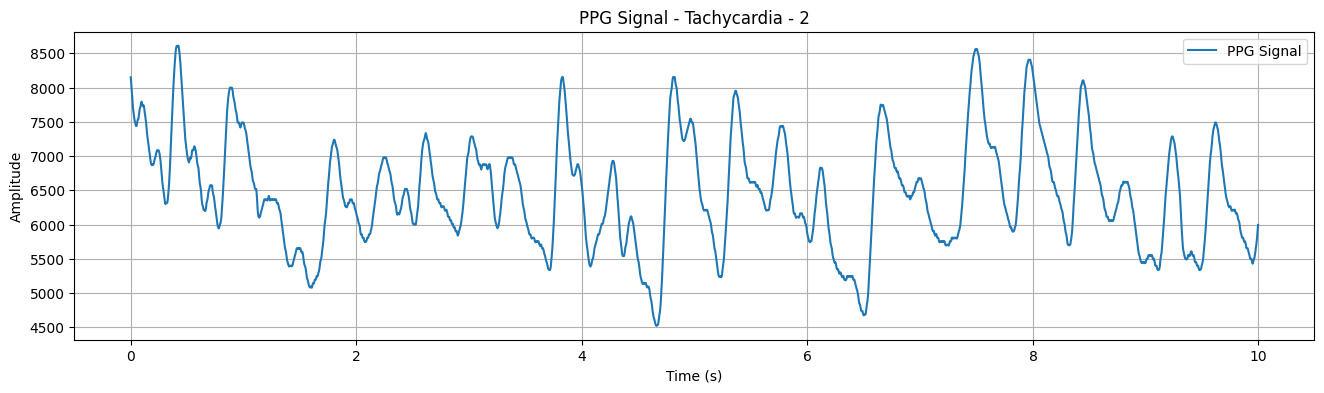

In [44]:
for n in range(1, 3):
    filename = ppg_df_segment['label'].iloc[n]
    title = f'PPG Signal - {filename} - {n}'
    signal = ppg_df_segment['ppg_signal'].iloc[n]
    fs = ppg_df_segment['frequency'].iloc[n]

    plot_ppg_signal(title, signal, fs, 0, 20)

### Convert to JSON Single File

In [45]:
import pandas as pd
import json
from pathlib import Path
import numpy as np

# Create output folder
output_dir = Path("PPG_CINC2015_MIMICAF_SEGMENT_250Hz")
output_dir.mkdir(exist_ok=True)

# Counters for each label
counters = {}

# Iterate through each row
for _, row in ppg_df_segment.iterrows():
    label = row['label']
    counters[label] = counters.get(label, 0) + 1
    num_str = f"{counters[label]:04d}"

    filename = f"data_{num_str}_{label.lower()}.json"
    filepath = output_dir / filename

    # Convert row to dict and make sure all NumPy arrays are turned into lists
    row_dict = row.to_dict()
    for k, v in row_dict.items():
        if isinstance(v, np.ndarray):
            row_dict[k] = v.tolist()
        elif isinstance(v, list) and any(isinstance(i, np.generic) for i in v):
            # Convert NumPy scalar values inside lists
            row_dict[k] = [i.item() if isinstance(i, np.generic) else i for i in v]

    with open(filepath, 'w') as f:
        json.dump(row_dict, f, indent=2)  # indent=2 for readability

In [ ]:
!zip -r /content/PPG_CINC2015_MIMICAF_SEGMENT_250Hz.zip /content/PPG_CINC2015_MIMICAF_SEGMENT_250Hz

## Save to Google Drive

In [47]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [48]:
!cp /content/PPG_CINC2015_MIMICAF_250Hz.json /content/drive/MyDrive/
!cp /content/PPG_CINC2015_MIMICAF_SEGMENT_250Hz.json /content/drive/MyDrive/
!cp /content/PPG_CINC2015_MIMICAF_SEGMENT_250Hz.zip /content/drive/MyDrive/